Tanimoto and cosine similarity

In [17]:
from sklearn.metrics.pairwise import cosine_similarity
import numpy as np
import os
import pandas as pd
import glob

def tanimoto_similarity_matrix(X, Y):
    """
    X: test fingerprints (n_test, n_bits)
    Y: train fingerprints (n_train, n_bits)
    """
    intersection = np.dot(X, Y.T)
    union = (
        X.sum(axis=1)[:, None]
        + Y.sum(axis=1)[None, :]
        - intersection
    )
    return intersection / union

For each aeid save a file of the test compounds with y true, y pred, cosine and tanimoto similarity

In [ ]:
### write a file for each aeid where we include y pred, y true, max cosine and tanimoto to the most similar training chemical ###

# --- Configuration ---
root_data_dir = r"Q:\Abteilungsprojekte\uchem\Projekte\Aktuelle Projekte\1179_MLinvitroTox\MLinvitroTox_PosNeg\mlinvitrotox\data\results\models\final_models_retrained\class"
fps = pd.read_csv(r"Q:\Abteilungsprojekte\uchem\Projekte\Aktuelle Projekte\1179_MLinvitroTox\MLinvitroTox_PosNeg\mlinvitrotox\data\results\models\final_models_retrained\ToxCast_True_FPS.csv")
fps = fps.drop("smiles", axis = 1)

# --- Data collection ---
results = []

target_aeid = "97"

for aeid_folder in os.listdir(root_data_dir):
    #if aeid_folder != target_aeid:
    #    continue
    if not aeid_folder.isdigit():
        continue

    aeid_path = os.path.join(root_data_dir, aeid_folder)
    if not os.path.isdir(aeid_path):
        continue

    fps_test_file = os.path.join(aeid_path, 'test_true_chemicals.csv')
    if not os.path.isfile(fps_test_file):
        continue
    fps_full_file = os.path.join(aeid_path, 'selected_chemicals.csv')
    if not os.path.isfile(fps_full_file):
        continue
    fps_test_df = pd.read_csv(fps_test_file)
    fps_test_df = fps_test_df.rename(columns={"0": "DTXSID"})
    fps_full_df = pd.read_csv(fps_full_file)
    fps_train_df = fps_full_df[~fps_full_df['DTXSID'].isin(fps_test_df["DTXSID"])]

    # --- load selected features ---
    features_path = os.path.join(
        aeid_path, "FS_RandomForest", "XGBClassifier", "selected_features.csv"
    )
    features_to_keep = pd.read_csv(features_path)

    columns_to_keep = features_to_keep["feature"].astype(str).tolist()

    # --- prepare fingerprints ---
    complete_fps = fps.copy()
    complete_fps = complete_fps.drop_duplicates(subset="DTXSID")
    complete_fps = complete_fps.set_index("DTXSID")

    # --- align exactly to train/test splits (order + length preserved) ---
    filtered_train = complete_fps.reindex(fps_train_df["DTXSID"])
    filtered_test  = complete_fps.reindex(fps_test_df["DTXSID"])

    # --- keep only fingerprint features ---
    filtered_train = filtered_train[columns_to_keep]
    filtered_test  = filtered_test[columns_to_keep]

    # Test Predictions
    predictions_path = os.path.join(aeid_path, "FS_RandomForest", "mb_val_structure", "test_predictions_default.csv") #for validation set
    pred_df = pd.read_csv(predictions_path)
    pred_df = pred_df.rename(columns={"0": "DTXSID"})

    # Convert to numpy
    X_train = (
        filtered_train
        .drop(columns=["DTXSID"], errors="ignore")
        .astype(float)
        .values
    )

    X_test = (
        filtered_test
        .drop(columns=["DTXSID"], errors="ignore")
        .astype(float)
        .values
    )

    # --- Tanimoto ---
    tanimoto_sim = tanimoto_similarity_matrix(X_test, X_train)
    max_tanimoto = tanimoto_sim.max(axis=1)

    # --- Cosine ---
    cosine_sim = cosine_similarity(X_test, X_train)
    max_cosine = cosine_sim.max(axis=1)
    similarity_df = pd.DataFrame({
        "DTXSID": filtered_test.index,
        "max_tanimoto": max_tanimoto,
        "max_cosine": max_cosine
    })
    pred_df["correct"] = (pred_df["y_true"] == pred_df["y_pred"]).astype(int)
    chemical_df = pred_df.merge(fps_test_df, left_index=True, right_index=True, how="inner")

    analysis_df = similarity_df.merge(chemical_df, on="DTXSID", how="inner")

    #analysis_df["correct"] = (analysis_df["y_true"] == analysis_df["y_pred"]).astype(int)

    analysis_df.to_csv(f'Q:\\Abteilungsprojekte\\uchem\\Projekte\\Aktuelle Projekte\\1179_MLinvitroTox\\MLinvitroTox_PosNeg\\similarity_fps\\{aeid_folder}_similarity.csv', index=False)


Similarity vs. balanced accuracy

In [25]:
analysis_df = pd.read_csv(r"Q:\Messdaten\EXPECTmine_data\02_MLinvitroTox_PosNeg\MLinvitroTox_PosNeg\src\mlinvitrotox\data\all_aeids_similarity_str_imp_fps.csv")
bins = np.linspace(0, 1, 11)  # fewer bins = stabler CI
analysis_df["sim_bin"] = pd.cut(analysis_df["max_tanimoto"], bins)

In [ ]:
### bootstrapping the metrics ###
from sklearn.metrics import balanced_accuracy_score

def bootstrap_balanced_accuracy(y_true, y_pred, n_bootstrap=1000, random_state=0):
    rng = np.random.default_rng(random_state)
    scores = []

    n = len(y_true)

    # Balanced accuracy needs both classes
    if len(np.unique(y_true)) < 2 or n < 5:
        return np.nan, np.nan, np.nan

    for _ in range(n_bootstrap):
        idx = rng.integers(0, n, n)
        y_t = y_true[idx]
        y_p = y_pred[idx]

        if len(np.unique(y_t)) < 2:
            continue

        scores.append(balanced_accuracy_score(y_t, y_p))

    if len(scores) == 0:
        return np.nan, np.nan, np.nan

    return (
        np.mean(scores),
        np.percentile(scores, 2.5),
        np.percentile(scores, 97.5),
    )


In [28]:
rows = []

for sim_bin, group in analysis_df.groupby("sim_bin", observed=True):
    mean_ba, ci_low, ci_high = bootstrap_balanced_accuracy(
        group["y_true"].values,
        group["y_pred"].values,
        n_bootstrap=1000
    )

    rows.append({
        "sim_bin": sim_bin,
        "balanced_accuracy": mean_ba,
        "ci_low": ci_low,
        "ci_high": ci_high,
        "n_samples": len(group)
    })

bin_stats = pd.DataFrame(rows)


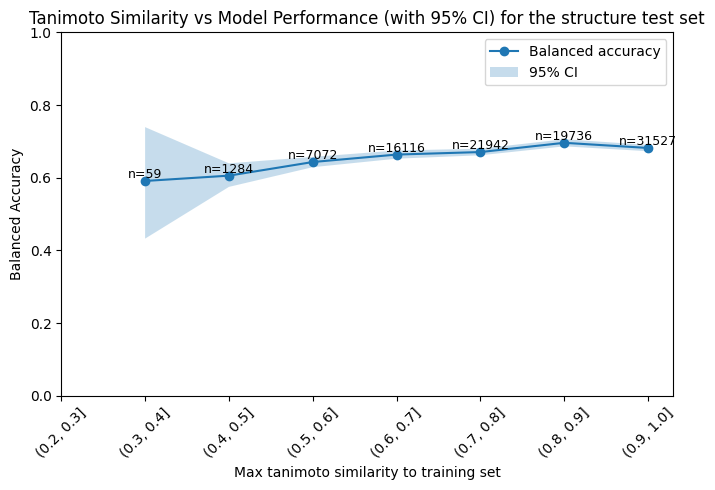

In [30]:
import matplotlib.pyplot as plt

x = np.arange(len(bin_stats))

plt.figure(figsize=(7,5))

plt.plot(
    x,
    bin_stats["balanced_accuracy"],
    marker="o",
    label="Balanced accuracy"
)

plt.fill_between(
    x,
    bin_stats["ci_low"],
    bin_stats["ci_high"],
    alpha=0.25,
    label="95% CI"
)

plt.xticks(x, bin_stats["sim_bin"].astype(str), rotation=45)

for i, n in enumerate(bin_stats["n_samples"]):
    plt.text(i, bin_stats["balanced_accuracy"].iloc[i], f"n={n}",
             ha="center", va="bottom", fontsize=9)

plt.xlabel("Max tanimoto similarity to training set")
plt.ylabel("Balanced Accuracy")
plt.ylim(0.0, 1)
plt.title("Tanimoto Similarity vs Model Performance (with 95% CI) for the structure test set")
plt.legend()
plt.tight_layout()
plt.show()


Number of test compounds that have tanimoto = 1 with training set

In [33]:
analysis_df_str = pd.read_csv(r"Q:\Messdaten\EXPECTmine_data\02_MLinvitroTox_PosNeg\MLinvitroTox_PosNeg\src\mlinvitrotox\data\all_aeids_similarity_str_imp_fps.csv")
analysis_df_pos = pd.read_csv(r"Q:\Messdaten\EXPECTmine_data\02_MLinvitroTox_PosNeg\MLinvitroTox_PosNeg\src\mlinvitrotox\data\all_aeids_similarity_pos_imp_fps.csv")
analysis_df_neg = pd.read_csv(r"Q:\Messdaten\EXPECTmine_data\02_MLinvitroTox_PosNeg\MLinvitroTox_PosNeg\src\mlinvitrotox\data\all_aeids_similarity_neg_imp_fps.csv")

In [34]:
analysis_df_combined = pd.concat(
    {
        "str": analysis_df_str,
        "pos": analysis_df_pos,
        "neg": analysis_df_neg,
    },
    names=["origin"]
).reset_index(level="origin").reset_index(drop=True)

<Figure size 800x500 with 0 Axes>

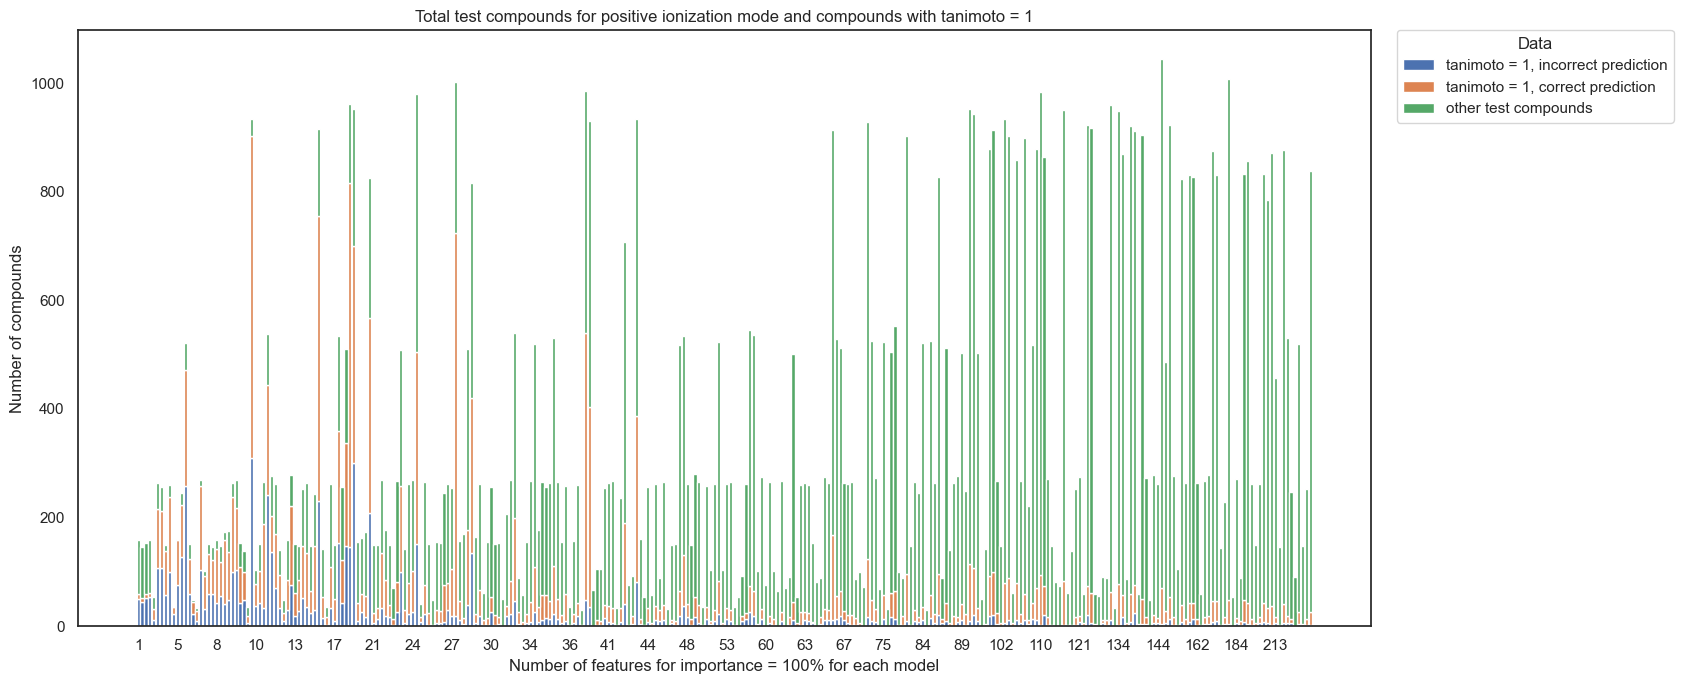

In [38]:
import matplotlib.pyplot as plt
# Rows where max_tanimoto == 1
df_filtered = analysis_df_str[analysis_df_str["max_tanimoto"] == 1]


# Counts for correct = 0 / 1 from filtered df
counts = (
    df_filtered
    .groupby(["AEID", "correct"])
    .size()
    .unstack(fill_value=0)
)

# Ensure both columns exist
counts = counts.reindex(columns=[0, 1], fill_value=0)

# Total row count from full analysis_df (all rows)
analysis_counts = analysis_df_str.groupby("AEID").size()

# Add missing AEIDs if needed
counts = counts.reindex(
    counts.index.union(analysis_counts.index),
    fill_value=0
)

analysis_counts = analysis_counts.reindex(counts.index, fill_value=0)

# EXTRA segment to stack on top:
# rows in analysis_df not already counted in df_filtered
extra_counts = analysis_counts - (counts[0] + counts[1])
extra_counts = extra_counts.clip(lower=0)

n_features = analysis_df_str.groupby("AEID")["n_features"].first()

# Sort AEIDs by n_features
sort_idx = n_features.sort_values().index

# Reorder everything
counts = counts.loc[sort_idx]
analysis_counts = analysis_counts.loc[sort_idx]
extra_counts = extra_counts.loc[sort_idx]
n_features = n_features.loc[sort_idx]

# Total height
total_height = counts[0] + counts[1] + extra_counts

fig, ax = plt.subplots(figsize=(17, 7))

x = range(len(n_features))

# Stacked bars
ax.bar(x, counts[0], label="tanimoto = 1, incorrect prediction")

ax.bar(
    x,
    counts[1],
    bottom=counts[0],
    label="tanimoto = 1, correct prediction"
)

ax.bar(
    x,
    extra_counts,
    bottom=counts[0] + counts[1],
    label="other test compounds"
)

# X ticks every 10
tick_idx = range(0, len(n_features), 10)

ax.set_xticks(tick_idx)

ax.set_xticklabels(
    n_features.iloc[tick_idx].astype(int)
)

# Labels and title
ax.set_xlabel("Number of features for importance = 100% for each model")
ax.set_ylabel("Number of compounds")

ax.set_title(
    "Total test compounds for positive ionization mode and compounds with tanimoto = 1"
)

# Optional: set y-limit manually
# ax.set_ylim(0, total_height.max() + 10)

# Legend
ax.legend(
    title="Data",
    bbox_to_anchor=(1.02, 1),
    loc="upper left",
    borderaxespad=0
)

plt.xticks(rotation=0)

plt.tight_layout()

plt.show()

In [39]:
# for all three modes together
df_filtered = analysis_df_combined[analysis_df_combined["max_tanimoto"] == 1]
counts = (
    df_filtered
    .groupby(["origin", "AEID", "correct"])
    .size()
    .unstack(fill_value=0)
)

analysis_counts = (
    analysis_df_combined
    .groupby(["origin", "AEID"])
    .size()
)

frac_t1 = (counts[0] + counts[1]) / analysis_counts

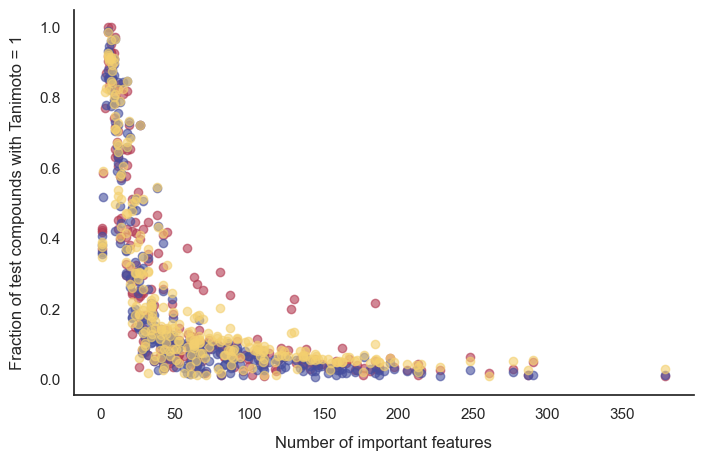

In [40]:
import seaborn as sns
plt.figure(figsize=(8, 5))

df_plot = frac_t1.copy()

mode_labels = {
    'str': 'Structure',
    'pos': 'Positive',
    'neg': 'Negative',
}

df_plot = df_plot.rename(
    index=mode_labels,
    level='origin',
)

sns.set(style="white")
colors = {
    "Structure": '#f4d06f',
    "Positive": '#454e9e',
    "Negative": '#b33951',
}

for origin in df_plot.index.get_level_values("origin").unique():
    y = df_plot.loc[origin]
    x = n_features.loc[y.index]

    plt.scatter(
        x,
        y,
        color=colors[origin],
        alpha=0.6,
        label=origin,
    )


sns.despine()


plt.xlabel("Number of important features", labelpad=10, fontsize=12)
plt.ylabel("Fraction of test compounds with Tanimoto = 1", labelpad=10, fontsize=12)

#plt.legend(title="Test set")
#plt.savefig("similarity_fps_all_test.svg", bbox_inches='tight')

plt.show()

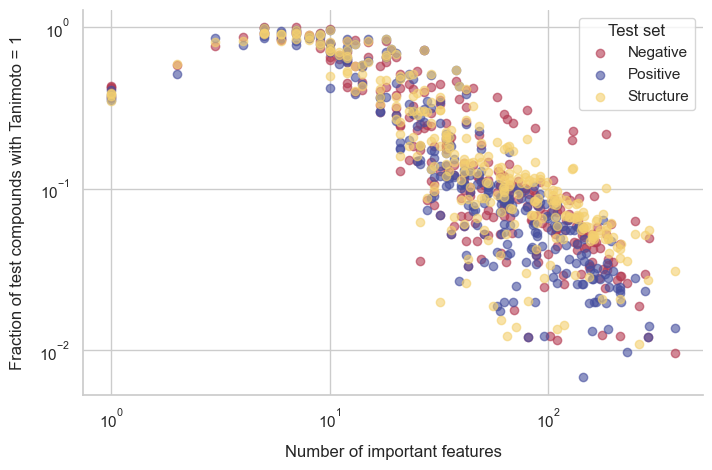

In [ ]:
# same but log scaled
plt.figure(figsize=(8, 5))

df_plot = frac_t1.copy()

mode_labels = {
    'str': 'Structure',
    'pos': 'Positive',
    'neg': 'Negative',
}

df_plot = df_plot.rename(
    index=mode_labels,
    level='origin',
)

sns.set(style="whitegrid")

colors = {
    "Structure": '#f4d06f',
    "Positive": '#454e9e',
    "Negative": '#b33951',
}

for origin in df_plot.index.get_level_values("origin").unique():
    y = df_plot.loc[origin]
    x = n_features.loc[y.index]

    plt.scatter(
        x,
        y,
        color=colors[origin],
        alpha=0.6,
        label=origin,
    )


sns.despine()
plt.xscale("log")
plt.yscale("log")

plt.xlabel("Number of important features", labelpad=10, fontsize=12)
plt.ylabel("Fraction of test compounds with Tanimoto = 1", labelpad=10, fontsize=12)

plt.legend(title="Test set")

plt.show()

Text(0, 0.5, 'Fraction Tanimoto = 1')

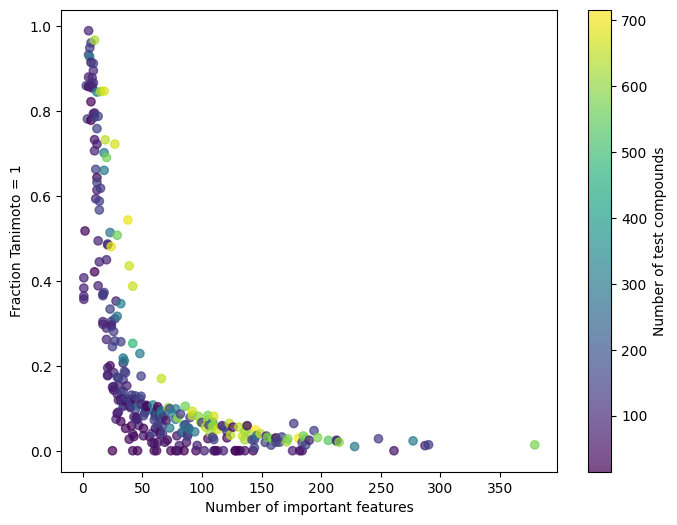

In [ ]:
# same but add the number of test compounds as color
plot_df = pd.DataFrame({
    "n_features": n_features,
    "total_compounds": analysis_counts,
    "frac_t1": frac_t1,
    "accuracy_t1": accuracy_t1
})
plt.figure(figsize=(8,6))

plt.scatter(
    plot_df["n_features"],
    plot_df["frac_t1"],
    #s=plot_df["total_compounds"],
    c=plot_df["total_compounds"],
    alpha=0.7
)

plt.colorbar(label="Number of test compounds")

plt.xlabel("Number of important features")
plt.ylabel("Fraction Tanimoto = 1")

SHAP plots for individual compounds

In [31]:
# -----------------------------------------------------------
# SHAP local explanations for test compounds (XGBoost model)
# -----------------------------------------------------------

import shap
import matplotlib.pyplot as plt
import joblib

test_df = pd.read_csv(r"Q:\Messdaten\EXPECTmine_data\02_MLinvitroTox_PosNeg\test_fps\107_test_fps.csv")
model = joblib.load(r"Q:\Messdaten\EXPECTmine_data\02_MLinvitroTox_PosNeg\mlinvitrotox\data\results\models\final_models_retrained\class\107\FS_RandomForest\XGBClassifier\best_estimator_train.joblib")
xgb_model = model.named_steps["XGBClassifier"]
# -----------------------------------------------------------
# 1. Separate identifiers and features
# -----------------------------------------------------------
id_col = "DTXSID"

X_test = test_df.drop(columns=[id_col])
compound_ids = test_df[id_col].values

# Ensure numeric
X_test = X_test.astype(float)
preprocessing_path = r"Q:\Messdaten\EXPECTmine_data\02_MLinvitroTox_PosNeg\mlinvitrotox\data\results\models\final_models_retrained\class\107\FS_RandomForest\preprocessing_model.joblib"
preprocessor = joblib.load(preprocessing_path)

X_pre = preprocessor.transform(X_test)

selector = model.named_steps["feature_selection"]

X_test_selected = selector.transform(X_pre)

pre_cols = preprocessor.get_feature_names_out()
selected_cols = pre_cols[selector.get_support()]

# -----------------------------------------------------------
# 2. Build SHAP explainer
# -----------------------------------------------------------
explainer = shap.TreeExplainer(xgb_model)

shap_values = explainer.shap_values(X_test_selected)

# If list, take positive class
if isinstance(shap_values, list):
    shap_vals = shap_values[1]
else:
    shap_vals = shap_values



c:\Users\aischlen\AppData\Local\anaconda3\envs\sirius_env\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
c:\Users\aischlen\AppData\Local\anaconda3\envs\sirius_env\Lib\pickle.py:1760: UserWarning: [14:20:23] WARNING: C:\actions-runner\_work\xgboost\xgboost\src\data\../common/error_msg.h:82: If you are loading a serialized model (like pickle in Python, RDS in R) or
configuration generated by an older version of XGBoost, please export the model by calling
`Booster.save_model` from that version first, then load it back in current version. See:

    https://xgboost.readthedocs.io/en/stable/tutorials/saving_model.html

for more details about differences between saving model and serializing.

  setstate(state)


Compound: DTXSID0023377


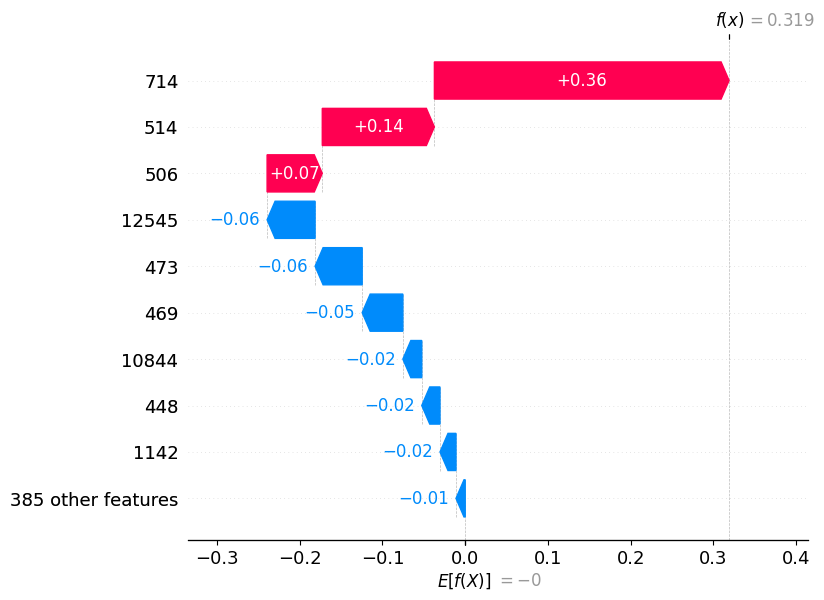

In [32]:
# -----------------------------------------------------------
# 3. Explain one compound by row index
# Example: first compound
# -----------------------------------------------------------
row_idx = 0
target_id = "DTXSID0023377"  #if I want to plot a specific dtxsid, replave row_idy with idy below
idx = test_df.index[test_df[id_col] == target_id][0]

print("Compound:", compound_ids[idx])

import matplotlib.pyplot as plt

plt.figure(figsize=(12, 8))

#waterfallplot
shap_explanation = shap.Explanation(
    values=shap_vals[idx],
    base_values=explainer.expected_value,
    feature_names=selected_cols,
)

shap.plots.waterfall(
    shap_explanation,
    show=False
)

#plt.savefig("shap_waterfall_0023377.pdf", dpi=300,bbox_inches="tight")
plt.show()